# Task 5: Student Feedback Classification with BERT

**Name:** Talha Aslam  **Roll No:** 24I-8067

**Problem.** A university receives hundreds of student feedback comments every semester, and reviewing each one by hand is slow. This notebook fine-tunes a pretrained **BERT (`bert-base-uncased`)** model to classify each comment automatically into one of five categories:

| Category | Example |
|---|---|
| Teaching Quality | "The instructor explains concepts clearly." |
| Laboratory Facilities | "The computer lab needs more systems." |
| Course Workload | "The course workload is too high." |
| IT Services | "The online portal frequently stops working." |
| Assessment & Grading | "The grading criteria are not clear." |

The first four categories come from the task sheet. **Assessment & Grading** was added because exam and marking complaints are very common in real feedback and don't fit cleanly into the other four.

**Where each task is in this notebook**

| Task | Section |
|---|---|
| Dataset preparation (train / validation / test) | 1, 3 |
| Text preprocessing (inspect, duplicates, missing/invalid) | 2 |
| BERT tokenization | 4 |
| Fine-tuning `bert-base-uncased` | 5 |
| Evaluation (accuracy, precision, recall, macro F1, confusion matrix) | 6 |
| Prediction on 12 new, unseen comments | 7 |
| Analysis (misclassifications, imbalance, limitations, improvements) | 8 |

Runtime: **GPU (T4)**. Training takes about 2–3 minutes.

In [15]:
# Colab already includes transformers / torch / sklearn; this makes sure they're present and recent.
!pip install -q transformers accelerate datasets scikit-learn seaborn

import os, random, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
MODEL_NAME = "bert-base-uncased"
os.environ["WANDB_DISABLED"] = "true"
print("Device:", "GPU - " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (switch to a GPU runtime for speed)")

Device: GPU - Tesla T4


## 1. Dataset

There is no public dataset for this exact task, so a labeled dataset of **298 student feedback comments** was created for this activity. The comments are written in the style of real university feedback: positive and negative, formal and informal ("Sir…", "Madam…"), and across many subjects and facilities.

The raw file is intentionally **realistic and messy**, so the preprocessing step has real work to do. It contains:
- exact and case/whitespace-variant **duplicates**,
- **missing / empty** comments and a missing label,
- **invalid** records: placeholder text (`N/A`), gibberish (`asdfgh`), one-word comments, and a label that isn't one of the five categories.

The classes are also **imbalanced** (e.g. Teaching Quality has more than twice as many comments as Assessment & Grading), which is common in real feedback.

The cell below writes the dataset to `student_feedback.csv`, so the notebook is self-contained.

In [16]:
%%writefile student_feedback.csv
feedback,category
The instructor provides detailed comments on our reports.,Teaching Quality
Lectures are engaging and the instructor checks our understanding regularly.,Teaching Quality
The teacher explains the same topic differently when students are confused.,Teaching Quality
The teacher encourages questions and discussion in class.,Teaching Quality
The lab equipment in the physics lab is broken.,Laboratory Facilities
The exam hall was noisy and the paper had printing mistakes.,Assessment & Grading
Lectures are well organized and easy to follow.,Teaching Quality
The lab needs proper ventilation.,Laboratory Facilities
The grading of the lab reports is too strict.,Assessment & Grading
The course registration system is very slow and unreliable.,IT Services
The number of lab tasks each week is too high.,Course Workload
Better lab facilities would improve our practical skills.,Laboratory Facilities
I wish the instructor used more diagrams to explain concepts.,Teaching Quality
Equipment in the lab should be upgraded to modern standards.,Laboratory Facilities
The online attendance system marks students absent incorrectly.,IT Services
The lab lights flicker and make it difficult to work.,Laboratory Facilities
The lab gets too crowded and students have to share one computer.,Laboratory Facilities
My portal account was locked and IT did not help.,IT Services
The lecturer is unprepared and often gets confused during class.,Teaching Quality
The VPN to access library journals does not connect.,IT Services
The portal goes down right before submission deadlines.,IT Services
IT support takes days to respond to complaints.,IT Services
We should have fewer but more meaningful assignments.,Course Workload
The internet connection in the hostel keeps disconnecting.,IT Services
Group project grades do not reflect individual contribution.,Assessment & Grading
This course has the heaviest workload of all my courses.,Course Workload
"We have three presentations and two projects in one course, which is too much.",Course Workload
The lab staff is not available when we need help with equipment.,Laboratory Facilities
Sessional marks were not shared before the final exam.,Assessment & Grading
The lab is too small for the number of students in our section.,Laboratory Facilities
The lecturer makes the subject interesting even though it is difficult.,Teaching Quality
Madam is very approachable during office hours.,Teaching Quality
The instructor explains complex topics with great clarity.,Teaching Quality
The instructor uses humor to keep the lectures lively.,Teaching Quality
The teacher makes the class interactive by asking us to solve problems on the board.,Teaching Quality
The final exam included topics that were never taught.,Assessment & Grading
The teacher shares helpful reading material after each class.,Teaching Quality
Our marks for the presentation were not explained.,Assessment & Grading
The professor helped me a lot when I was falling behind.,Teaching Quality
Assessments should include more practical tasks instead of only written exams.,Assessment & Grading
The instructor gives personal attention to students who are struggling.,Teaching Quality
There are too many group projects at the same time.,Course Workload
The instructor speaks too fast and it is hard to take notes.,Teaching Quality
The fume hoods in the chemistry lab are not functioning.,Laboratory Facilities
The result portal shows wrong information sometimes.,IT Services
The timetable on the portal is not updated on time.,IT Services
Different teaching assistants grade the same assignment differently.,Assessment & Grading
The number of quizzes in this course is overwhelming.,Course Workload
The online submission system rejects PDF files for no reason.,IT Services
Zoom links on the LMS are often broken.,IT Services
The university should upgrade its servers because the portal is always slow.,IT Services
Lab manuals are outdated and do not match the equipment.,Laboratory Facilities
New lab equipment has made practicals much better this semester.,Laboratory Facilities
Software licenses provided by the university have expired.,IT Services
The lab temperature is too hot in summer to work properly.,Laboratory Facilities
Exams test memorization rather than understanding.,Assessment & Grading
The professor explains concepts using simple language.,Teaching Quality
I could not understand most lectures because the explanations were unclear.,Teaching Quality
Grading is fair and transparent.,Assessment & Grading
The instructor was unclear about key concepts in the first half of the course.,Teaching Quality
The teacher's accent makes it difficult to follow the lecture.,Teaching Quality
  THE INSTRUCTOR IS RESPECTFUL AND TREATS ALL STUDENTS FAIRLY.  ,Teaching Quality
The university website loads very slowly.,IT Services
The teacher only focuses on the top students.,Teaching Quality
Uploading files on the LMS takes too long.,IT Services
The lecturer could improve by being more organized.,Teaching Quality
Marks for assignments are released very late.,Assessment & Grading
The instructor ignores students who ask questions.,Teaching Quality
There is no Wi-Fi coverage in the cafeteria.,IT Services
The project load is too heavy for a single semester.,Course Workload
Teaching quality in this course is excellent.,Teaching Quality
There are not enough chemicals and apparatus in the chemistry lab.,Laboratory Facilities
The workload is reasonable and manageable.,Course Workload
The lab cabinet locks are broken and equipment goes missing.,Laboratory Facilities
The student portal does not work on mobile browsers.,IT Services
Weekly case study write-ups are too much on top of the project.,Course Workload
The air conditioning in the lab does not work.,Laboratory Facilities
Notifications from the portal arrive late.,IT Services
There is no proper safety equipment in the chemistry lab.,Laboratory Facilities
Explanations in lectures are confusing and lack structure.,Teaching Quality
The course has too many small tasks that consume a lot of time.,Course Workload
Lab timings are too short to complete our experiments.,Laboratory Facilities
Past papers should be provided to help us prepare.,Assessment & Grading
The teacher always welcomes questions after class.,Teaching Quality
I could not keep up with the volume of work in this course.,Course Workload
Surprise quizzes are unfair because we cannot prepare.,Assessment & Grading
The midterm results took more than a month to announce.,Assessment & Grading
The lab lacks basic components like resistors and breadboards.,Laboratory Facilities
Our professor makes even difficult topics easy to understand.,Teaching Quality
Sir should give more time to solving examples in class.,Teaching Quality
Weekly assignments plus quizzes plus a project is excessive.,Course Workload
The internet speed on campus is too slow for video lectures.,IT Services
Deadlines for different assignments overlap too often.,Course Workload
I did not get any explanation for the marks deducted in my exam.,Assessment & Grading
The online portal is slow during peak hours.,IT Services
More microscopes are needed in the biology lab.,Laboratory Facilities
The lab headphones are broken so we cannot do the language lab exercises.,Laboratory Facilities
The midterm paper was too lengthy to finish on time.,Assessment & Grading
The portal's search feature does not find my courses.,IT Services
Lectures are clear but the instructor could provide more examples.,Teaching Quality
The Wi-Fi in the hostel is unusable at night.,IT Services
The teacher is friendly and creates a comfortable learning environment.,Teaching Quality
The coding assignments take far too long to complete.,Course Workload
The instructor clearly communicates what we are expected to learn.,Teaching Quality
Class discussions were engaging and helped me understand the material.,Teaching Quality
The portal is slow on weekends.,Portal Issue
Marking scheme for the viva was not consistent.,Assessment & Grading
There are not enough lab seats for all students to work individually.,Laboratory Facilities
The teacher always welcomes questions after class.,Teaching Quality
,Laboratory Facilities
Recorded lectures on the LMS do not play properly.,IT Services
The amount of homework leaves no time for other subjects.,Course Workload
Re-checking requests are ignored.,Assessment & Grading
The course workload is too high.,Course Workload
Lab sessions are affected because half the systems do not boot.,Laboratory Facilities
The course requires too many hours of practice every day.,Course Workload
The lab equipment is old and often breaks during experiments.,Laboratory Facilities
I learned a lot from the way the professor connected theory with practice.,Teaching Quality
The number of tasks per week should be reduced.,Course Workload
The instructor's explanations of the theory are very clear and thorough.,Teaching Quality
There is a lot of work outside class hours.,Course Workload
Online quizzes on the LMS freeze in the middle.,IT Services
The professor is very knowledgeable about the subject.,Teaching Quality
The instructor ignores students who ask questions.,Teaching Quality
The LMS sends too many duplicate emails.,IT Services
The Wi-Fi does not work in the library.,IT Services
The instructor explains concepts clearly.,Teaching Quality
There are too many deadlines in the same week.,Course Workload
The online portal shows an error when I try to download my transcript.,IT Services
The portal does not allow uploading files larger than a few MB.,IT Services
The professor relates the course to industry applications.,Teaching Quality
The weightage of the final exam is too high.,Assessment & Grading
The computer lab should have more machines with Linux installed.,Laboratory Facilities
Lectures feel like the instructor is just reading a textbook.,Teaching Quality
,Teaching Quality
The teacher only focuses on the top students.,Teaching Quality
The email service often delays important announcements.,IT Services
I spend more than twenty hours a week on this course alone.,Course Workload
The lab is fine.,
"The teacher summarizes the key points at the end of each lecture, which helps a lot.",Teaching Quality
The final project is too large to complete in two weeks.,Course Workload
The portal logs us out while we are submitting assignments.,IT Services
The university Wi-Fi is very slow in the classrooms.,IT Services
I could not access my university email account for a week.,IT Services
Assignments are very lengthy and time consuming.,Course Workload
The quiz time limit was too short for the number of questions.,Assessment & Grading
The teacher does not respond to emails or questions outside class.,Teaching Quality
The exams were much harder than what was taught in class.,Assessment & Grading
The grading was done carefully and fairly.,Assessment & Grading
Many computers in the lab are outdated and very slow.,Laboratory Facilities
"The workload is unbalanced, with everything due near the end of the semester.",Course Workload
The lab benches are damaged and need repair.,Laboratory Facilities
We get too many assignments every week.,Course Workload
The IT department fixed my login issue very quickly.,IT Services
The professor's explanations of algorithms were excellent.,Teaching Quality
The instructor provides useful feedback on assignments.,Teaching Quality
The online fee payment system shows errors.,IT Services
The teacher's feedback on my presentation helped me improve.,Teaching Quality
   ,Course Workload
The workload in this course is fair compared to other courses.,Course Workload
Marks are not uploaded on time on the portal.,Assessment & Grading
The teacher reads directly from the slides and does not explain anything.,Teaching Quality
The workload was heavy but it helped me learn.,Course Workload
The workload became unmanageable in the second half of the semester.,Course Workload
The course expects us to cover too many chapters every week.,Course Workload
The professor cancels classes frequently without informing us.,Teaching Quality
Lectures lack depth and only cover the basics.,Teaching Quality
The portal should be more user friendly.,IT Services
The professor knows how to make a large class feel engaged.,Teaching Quality
The projector in the lab is not working for weeks.,Laboratory Facilities
Lab assistants are helpful when equipment does not work.,Laboratory Facilities
The mechanical workshop needs better tools.,Laboratory Facilities
The course demands are realistic and well planned.,Course Workload
Network issues in classrooms make online demonstrations impossible.,IT Services
The robotics lab has very few working kits.,Laboratory Facilities
good,Teaching Quality
The professor's voice is too low to hear from the back of the room.,Teaching Quality
The project and assignments together take too much time.,Course Workload
We need more GPUs in the lab for deep learning assignments.,Laboratory Facilities
The helpdesk ticket system never updates the status of my complaint.,IT Services
The streaming of online classes keeps buffering due to poor internet.,IT Services
The instructor is enthusiastic and makes the class enjoyable.,Teaching Quality
The Wi-Fi password changes without notice.,IT Services
The new machines in the computer lab are fast and reliable.,Laboratory Facilities
Lab instruments are not calibrated properly so results are wrong.,Laboratory Facilities
  LAB MANUALS ARE OUTDATED AND DO NOT MATCH THE EQUIPMENT.  ,Laboratory Facilities
The professor's teaching motivated me to study this field further.,Teaching Quality
Quiz questions are out of syllabus.,Assessment & Grading
The professor's lectures are inspiring and well delivered.,Teaching Quality
The online registration crashed on the first day of enrollment.,IT Services
There was no chance to review our graded answer sheets.,Assessment & Grading
The instructor is respectful and treats all students fairly.,Teaching Quality
I feel stressed because of the constant assignments.,Course Workload
I appreciate how the teacher checks whether everyone understood before moving on.,Teaching Quality
The lab is well equipped and maintained.,Laboratory Facilities
The biology lab needs fresh specimens and better storage.,Laboratory Facilities
Sir always comes prepared and uses good real-life examples.,Teaching Quality
The electronics lab needs new oscilloscopes.,Laboratory Facilities
Internet access in the computer center is unstable.,IT Services
The networking lab lacks routers and switches for practicals.,Laboratory Facilities
The online portal frequently stops working.,IT Services
The instructor gives constructive feedback that helps me improve.,Teaching Quality
The rubric for the project was never shared with us.,Assessment & Grading
Too much self-study is expected for this course.,Course Workload
This course requires more effort than other courses with the same credit hours.,Course Workload
Too many quizzes and assignments are scheduled during midterm week.,Course Workload
The professor gives real-world case studies that make the topics memorable.,Teaching Quality
There is too much work for the marks it carries.,Course Workload
The internet connection in the hostel keeps disconnecting.,IT Services
The instructor uses interactive activities that keep students interested.,Teaching Quality
The teaching style is monotonous and boring.,Teaching Quality
The assignments are fine but there are too many of them.,Course Workload
The workload could be reduced by combining some assignments.,Course Workload
The lab printer never has paper or toner.,Laboratory Facilities
The instructor is punctual and well prepared for every class.,Teaching Quality
N/A,IT Services
The new LMS update has made the portal much faster.,IT Services
The lecturer repeats the same point many times without clarifying it.,Teaching Quality
The monitors in the lab are too small and have dead pixels.,Laboratory Facilities
IT helpdesk staff are cooperative and solve problems quickly.,IT Services
The campus Wi-Fi requires logging in again every hour.,IT Services
The exam questions were ambiguous and confusing.,Assessment & Grading
The syllabus is too heavy for a three credit hour course.,Course Workload
Several keyboards and mice in the computer lab are not working.,Laboratory Facilities
We barely get time to rest because of the assignments.,Course Workload
Single sign-on does not work for the LMS and email.,IT Services
The computer lab needs more systems.,Laboratory Facilities
The plagiarism checker on the portal does not open.,IT Services
Assignment marks are inconsistent between sections.,Assessment & Grading
The campus Wi-Fi requires logging in again every hour.,IT Services
The reading assignments are too long to complete every week.,Course Workload
The course covers too much content in one semester.,Course Workload
The university app crashes on my phone.,IT Services
Our teacher is patient and explains things again when we do not understand.,Teaching Quality
Workload should be distributed evenly throughout the semester.,Course Workload
The instructor often arrives late to class.,Teaching Quality
The grading criteria are not clear.,Assessment & Grading
The lab computers have very low RAM and cannot run the required tools.,Laboratory Facilities
The assessment methods are well balanced.,Assessment & Grading
The instructor is too strict and students are afraid to ask questions.,Teaching Quality
The final exam was well designed and covered the course fairly.,Assessment & Grading
Password reset on the portal never works.,IT Services
The instructor does not engage with the class at all.,Teaching Quality
There are not enough power sockets in the lab for laptops.,Laboratory Facilities
The circuit lab needs more multimeters.,Laboratory Facilities
The paper pattern was changed without telling us.,Assessment & Grading
The professor gives clear examples before moving to complex problems.,Teaching Quality
The course pace is too fast and the workload keeps piling up.,Course Workload
Too many quizzes and assignments are scheduled during midterm week.,Course Workload
  THE EXAM QUESTIONS WERE AMBIGUOUS AND CONFUSING.  ,Assessment & Grading
I cannot log in to the student portal most of the time.,IT Services
The software installed in the lab computers is outdated.,Laboratory Facilities
The student email storage is too small.,IT Services
The lab whiteboard markers are always missing.,Laboratory Facilities
The lab sinks are blocked and water leaks on the floor.,Laboratory Facilities
The relative grading system is unfair to hardworking students.,Assessment & Grading
The professor answers questions patiently and in detail.,Teaching Quality
We need more lab slots because one weekly session is not enough.,Laboratory Facilities
The exam hall was noisy and the paper had printing mistakes.,Assessment & Grading
The lab facilities are good but need more maintenance.,Laboratory Facilities
Assignments are given with very short deadlines.,Course Workload
The LMS crashes when many students try to submit assignments.,IT Services
Microsoft Office accounts given by the university do not activate.,IT Services
The campus network is down almost every week.,IT Services
We receive new assignments before the previous ones are graded.,Course Workload
IT services should provide better internet bandwidth.,IT Services
The exam schedule gives no gap between papers.,Assessment & Grading
The lab chairs are uncomfortable and broken.,Laboratory Facilities
  OUR TEACHER IS PATIENT AND EXPLAINS THINGS AGAIN WHEN WE DO NOT UNDERSTAND.  ,Teaching Quality
The instructor never finishes the lecture on time and skips topics.,Teaching Quality
The instructor's guidance during the project was really valuable.,Teaching Quality
The online portal is easy to use and works well.,IT Services
The lab computers do not have MATLAB installed.,Laboratory Facilities
The teacher motivates students to think critically.,Teaching Quality
The lab should remain open in the evenings for practice.,Laboratory Facilities
The workload is light and the course is easy to manage.,Course Workload
The lecturer's examples are outdated and not relevant.,Teaching Quality
Attendance marks are deducted unfairly.,Assessment & Grading
The teacher should explain the practical relevance of the topics.,Teaching Quality
asdfgh,IT Services
The weekly lab reports add a lot of extra work.,Course Workload
"The professor does not explain how to approach problems, only the final answers.",Teaching Quality
The professor explains the reasoning behind every formula.,Teaching Quality
The physics lab is clean and well organized.,Laboratory Facilities
The lecturer is passionate about the subject and it shows.,Teaching Quality
The LMS interface is confusing and outdated.,IT Services
Concepts are explained step by step which makes learning easier.,Teaching Quality
Students have to wait a long time to use the lab equipment.,Laboratory Facilities
The professor goes off topic too often during lectures.,Teaching Quality
The teacher rushes through important topics.,Teaching Quality
The online exam system crashed during the midterm.,IT Services
The professor's explanations of algorithms were excellent.,Teaching Quality
The teaching was the best part of this course.,Teaching Quality
The electrical lab has unsafe wiring that should be fixed.,Laboratory Facilities
The instructor gives practical tips that are very helpful.,Teaching Quality
Campus internet blocks websites we need for research.,IT Services
The online library system is often unavailable.,IT Services
The lecturer explains proofs in a very clear and logical way.,Teaching Quality

Overwriting student_feedback.csv


In [17]:
raw = pd.read_csv("student_feedback.csv", keep_default_na=True)
print("Raw shape:", raw.shape)
display(raw.head(10))
raw.info()

Raw shape: (298, 2)


,feedback,category
0,The instructor provides detailed comments on our reports.,Teaching Quality
1,Lectures are engaging and the instructor checks our understanding regularly.,Teaching Quality
2,The teacher explains the same topic differently when students are confused.,Teaching Quality
3,The teacher encourages questions and discussion in class.,Teaching Quality
4,The lab equipment in the physics lab is broken.,Laboratory Facilities
5,The exam hall was noisy and the paper had printing mistakes.,Assessment & Grading
6,Lectures are well organized and easy to follow.,Teaching Quality
7,The lab needs proper ventilation.,Laboratory Facilities
8,The grading of the lab reports is too strict.,Assessment & Grading
9,The course registration system is very slow and unreliable.,IT Services


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 298 entries, 0 to 297
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   feedback  295 non-null    object
 1   category  297 non-null    object
dtypes: object(2)
memory usage: 4.8+ KB


## 2. Text preprocessing: inspecting and cleaning the data

In [18]:
CATEGORIES = ["Teaching Quality", "Laboratory Facilities", "Course Workload", "IT Services", "Assessment & Grading"]
df = raw.copy()
log = [("Raw records", len(df))]

# 1) Missing values
print("Missing values per column:\n", df.isna().sum(), "\n")
df = df.dropna(subset=["feedback", "category"])
log.append(("After dropping missing feedback/label", len(df)))

# 2) Normalise whitespace, then drop empty strings
df["feedback"] = df["feedback"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
df["category"] = df["category"].astype(str).str.strip()
df = df[df["feedback"] != ""]
log.append(("After dropping empty comments", len(df)))

# 3) Invalid labels (not one of the predefined categories)
bad_labels = df[~df["category"].isin(CATEGORIES)]
print("Invalid labels found:\n", bad_labels, "\n")
df = df[df["category"].isin(CATEGORIES)]
log.append(("After removing invalid labels", len(df)))

# 4) Invalid / uninformative text: placeholders, gibberish or fewer than 3 words
placeholders = {"n/a", "na", "none", "nil", "-", "."}
def is_invalid(t):
    words = re.findall(r"[a-zA-Z]+", t)
    return t.lower() in placeholders or len(words) < 3
invalid = df[df["feedback"].apply(is_invalid)]
print("Invalid / too-short comments removed:\n", invalid, "\n")
df = df[~df["feedback"].apply(is_invalid)]
log.append(("After removing invalid/too-short text", len(df)))

# 5) Duplicates (case-insensitive, after whitespace normalisation)
df["_key"] = df["feedback"].str.lower()
n_dup = df.duplicated(subset="_key").sum()
print(f"Duplicate comments found: {n_dup}")
# keep the normally-written copy rather than an ALL-CAPS variant
df = (df.assign(_caps=df["feedback"].str.isupper()).sort_values("_caps", kind="stable")
        .drop_duplicates(subset="_key").sort_index().drop(columns=["_key", "_caps"]).reset_index(drop=True))
log.append(("After removing duplicates", len(df)))

display(pd.DataFrame(log, columns=["Step", "Records"]))

Missing values per column:
 feedback    3
category    1
dtype: int64 

Invalid labels found:
                             feedback      category
105  The portal is slow on weekends.  Portal Issue 

Invalid / too-short comments removed:
     feedback          category
175     good  Teaching Quality
279   asdfgh       IT Services 

Duplicate comments found: 12


,Step,Records
0,Raw records,298
1,After dropping missing feedback/label,294
2,After dropping empty comments,293
3,After removing invalid labels,292
4,After removing invalid/too-short text,290
5,After removing duplicates,278


,count,percent
category,,
Teaching Quality,80,28.8
Laboratory Facilities,55,19.8
Course Workload,48,17.3
IT Services,60,21.6
Assessment & Grading,35,12.6


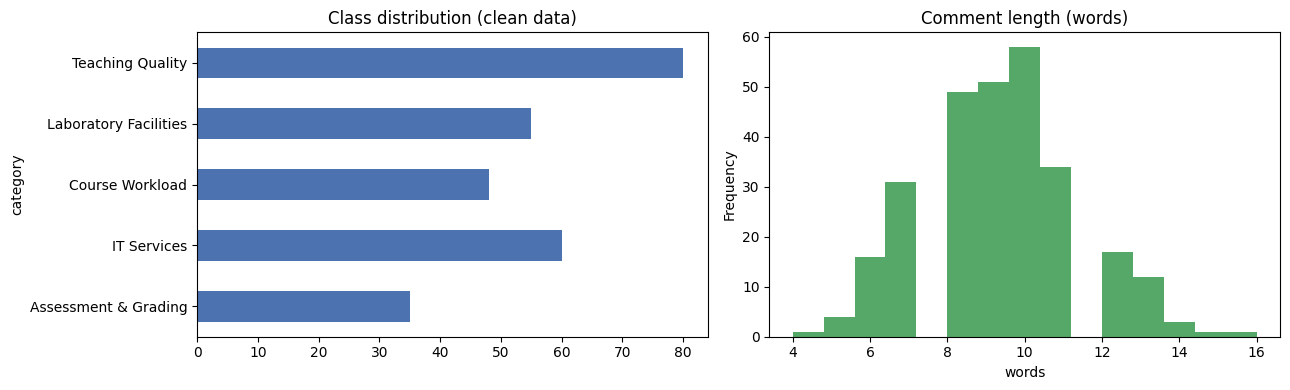

Imbalance ratio (largest / smallest class): 2.29


In [19]:
counts = df["category"].value_counts().reindex(CATEGORIES)
display(counts.to_frame("count").assign(percent=lambda x: (100 * x["count"] / x["count"].sum()).round(1)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Class distribution (clean data)"); ax[0].invert_yaxis()
df["feedback"].str.split().str.len().plot.hist(bins=15, ax=ax[1], color="#55A868")
ax[1].set_title("Comment length (words)"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.2f}")

## 3. Train / validation / test split

A **stratified 70 / 15 / 15** split keeps the class proportions the same in every subset. That matters here because the classes are imbalanced. The validation set is used to choose the best epoch, and the test set is only used once, for the final evaluation.

In [20]:
label2id = {c: i for i, c in enumerate(CATEGORIES)}
id2label = {i: c for c, i in label2id.items()}
df["label"] = df["category"].map(label2id)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

split_table = pd.DataFrame({
    "train": train_df["category"].value_counts(),
    "validation": val_df["category"].value_counts(),
    "test": test_df["category"].value_counts()}).reindex(CATEGORIES)
split_table.loc["Total"] = split_table.sum()
display(split_table)

,train,validation,test
category,,,
Teaching Quality,56,12,12
Laboratory Facilities,38,8,9
Course Workload,34,7,7
IT Services,42,9,9
Assessment & Grading,24,6,5
Total,194,42,42


## 4. BERT tokenization

We use the tokenizer that belongs to `bert-base-uncased`. It lowercases the text, splits it into **WordPiece** sub-word tokens, adds the special `[CLS]` and `[SEP]` tokens, and maps each token to its vocabulary ID. The classifier reads the final hidden state of the `[CLS]` token.

In [21]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = "The LMS crashes when many students submit assignments."
enc = tokenizer(example)
print("Text      :", example)
print("Tokens    :", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("Input IDs :", enc["input_ids"])

lengths = [len(tokenizer(t)["input_ids"]) for t in df["feedback"]]
print(f"\nToken length: max={max(lengths)}, mean={np.mean(lengths):.1f}, 95th pct={np.percentile(lengths, 95):.0f}")
MAX_LEN = 64   # comfortably covers every comment, so nothing is truncated

Text      : The LMS crashes when many students submit assignments.
Tokens    : ['[CLS]', 'the', 'l', '##ms', 'crashes', 'when', 'many', 'students', 'submit', 'assignments', '.', '[SEP]']
Input IDs : [101, 1996, 1048, 5244, 19119, 2043, 2116, 2493, 12040, 14799, 1012, 102]

Token length: max=22, mean=12.9, 95th pct=16


In [22]:
def to_dataset(frame):
    return Dataset.from_pandas(frame[["feedback", "label"]].reset_index(drop=True))

def tokenize(batch):
    return tokenizer(batch["feedback"], truncation=True, max_length=MAX_LEN)

train_ds = to_dataset(train_df).map(tokenize, batched=True)
val_ds   = to_dataset(val_df).map(tokenize, batched=True)
test_ds  = to_dataset(test_df).map(tokenize, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)   # dynamic padding per batch
print(train_ds)

Map:   0%|          | 0/194 [00:00<?, ? examples/s]

Map:   0%|          | 0/42 [00:00<?, ? examples/s]

Map:   0%|          | 0/42 [00:00<?, ? examples/s]

Dataset({
    features: ['feedback', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 194
})


## 5. Fine-tuning `bert-base-uncased`

`AutoModelForSequenceClassification` loads the pretrained BERT encoder and adds a new **linear classification head** (768 → 5) on top of the `[CLS]` representation. The whole network is then fine-tuned with cross-entropy loss.

| Hyperparameter | Value | Reason |
|---|---|---|
| Learning rate | 2e-5 | standard for BERT fine-tuning (BERT paper recommends 2e-5 – 5e-5) |
| Batch size | 16 | small dataset, fits easily on a T4 |
| Epochs | 6 | small dataset needs a few passes; the best epoch is kept |
| Weight decay / warm-up | 0.01 / 10% | regularisation and stable start |
| Model selection | best **validation macro-F1** | macro-F1 treats all classes equally, so it's a better guide than accuracy for imbalanced data |

In [23]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(CATEGORIES), id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "macro_f1": f1}

EPOCHS, BATCH = 12, 16
warmup = int(0.1 * EPOCHS * np.ceil(len(train_ds) / BATCH))   # 10% of all training steps

args = TrainingArguments(
    output_dir="bert-feedback",
    learning_rate=4e-5,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=32,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    warmup_steps=warmup,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_strategy="epoch",
    seed=SEED,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  processing_class=tokenizer, data_collator=collator, compute_metrics=compute_metrics)
train_result = trainer.train()
print(train_result)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,1.545205,1.365879,0.523810,0.376092,0.427778,0.358221
2,1.240662,1.095045,0.547619,0.348070,0.450000,0.351299
3,0.949952,0.736403,0.785714,0.683333,0.714286,0.676883
4,0.582909,0.396927,0.952381,0.959615,0.933333,0.938667
5,0.240642,0.200901,0.976190,0.971429,0.971429,0.969231
6,0.100241,0.053817,1.000000,1.000000,1.000000,1.000000
7,0.033414,0.034480,1.000000,1.000000,1.000000,1.000000
8,0.018187,0.015692,1.000000,1.000000,1.000000,1.000000
9,0.014044,0.012906,1.000000,1.000000,1.000000,1.000000
10,0.011607,0.011854,1.000000,1.000000,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=156, training_loss=0.3964514130583176, metrics={'train_runtime': 162.8592, 'train_samples_per_second': 14.295, 'train_steps_per_second': 0.958, 'total_flos': 20578716595368.0, 'train_loss': 0.3964514130583176, 'epoch': 12.0})


,epoch,eval_loss,eval_accuracy,eval_macro_f1
0,1.0,1.3659,0.5238,0.3582
1,2.0,1.0950,0.5476,0.3513
2,3.0,0.7364,0.7857,0.6769
3,4.0,0.3969,0.9524,0.9387
4,5.0,0.2009,0.9762,0.9692
5,6.0,0.0538,1.0000,1.0000
6,7.0,0.0345,1.0000,1.0000
7,8.0,0.0157,1.0000,1.0000
8,9.0,0.0129,1.0000,1.0000
9,10.0,0.0119,1.0000,1.0000


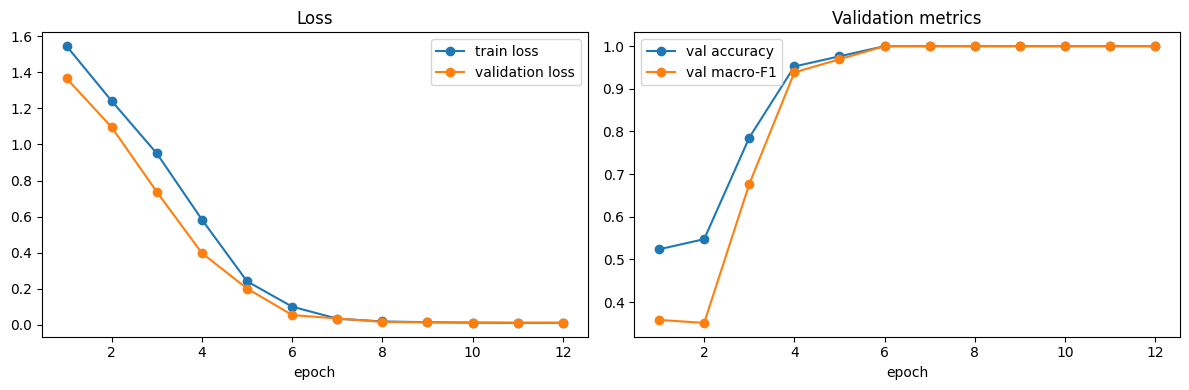

In [24]:
hist = pd.DataFrame(trainer.state.log_history)
tr = hist.dropna(subset=["loss"])[["epoch", "loss"]]
ev = hist.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]
display(ev.round(4).reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tr["epoch"], tr["loss"], "o-", label="train loss")
ax[0].plot(ev["epoch"], ev["eval_loss"], "o-", label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(ev["epoch"], ev["eval_accuracy"], "o-", label="val accuracy")
ax[1].plot(ev["epoch"], ev["eval_macro_f1"], "o-", label="val macro-F1")
ax[1].set_xlabel("epoch"); ax[1].set_title("Validation metrics"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Evaluation on the held-out test set

In [25]:
pred_out = trainer.predict(test_ds)
y_true = pred_out.label_ids
probs = torch.softmax(torch.tensor(pred_out.predictions), dim=-1).numpy()
y_pred = probs.argmax(axis=1)

acc = accuracy_score(y_true, y_pred)
p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
display(pd.DataFrame({"Accuracy": [acc], "Precision (macro)": [p_m], "Recall (macro)": [r_m],
                      "Macro F1": [f1_m], "Weighted F1": [f1_w]}).round(4))

print(classification_report(y_true, y_pred, target_names=CATEGORIES, digits=3, zero_division=0))

,Accuracy,Precision (macro),Recall (macro),Macro F1,Weighted F1
0,0.9286,0.9386,0.8978,0.9049,0.9251


                       precision    recall  f1-score   support

     Teaching Quality      1.000     1.000     1.000        12
Laboratory Facilities      1.000     0.889     0.941         9
      Course Workload      0.875     1.000     0.933         7
          IT Services      0.818     1.000     0.900         9
 Assessment & Grading      1.000     0.600     0.750         5

             accuracy                          0.929        42
            macro avg      0.939     0.898     0.905        42
         weighted avg      0.940     0.929     0.925        42



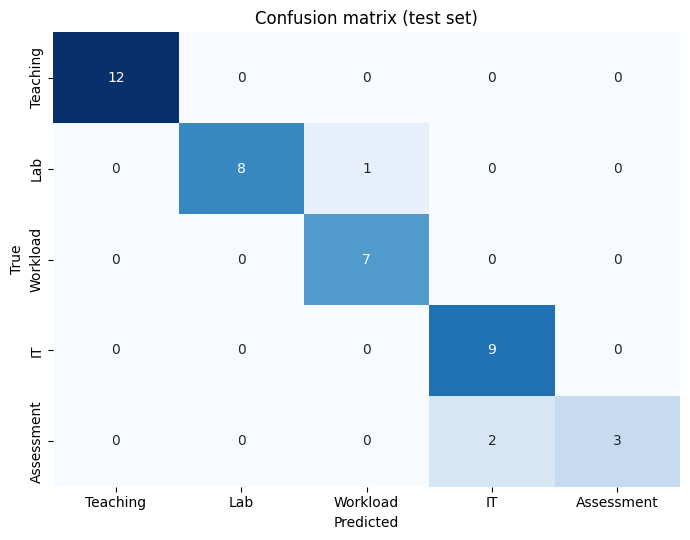

In [26]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(CATEGORIES)))
short = ["Teaching", "Lab", "Workload", "IT", "Assessment"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=short, yticklabels=short, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()

In [27]:
test_view = test_df.reset_index(drop=True).copy()
test_view["predicted"] = [id2label[i] for i in y_pred]
test_view["confidence"] = probs.max(axis=1).round(3)
wrong = test_view[test_view["category"] != test_view["predicted"]][["feedback", "category", "predicted", "confidence"]]
print(f"Misclassified: {len(wrong)} of {len(test_view)} test comments")
pd.set_option("display.max_colwidth", None)
display(wrong)

print("Lowest-confidence test predictions (where the model is least sure):")
display(test_view.nsmallest(5, "confidence")[["feedback", "category", "predicted", "confidence"]])

Misclassified: 3 of 42 test comments


,feedback,category,predicted,confidence
18,Marks are not uploaded on time on the portal.,Assessment & Grading,IT Services,0.959
23,Lab timings are too short to complete our experiments.,Laboratory Facilities,Course Workload,0.526
35,Re-checking requests are ignored.,Assessment & Grading,IT Services,0.913


Lowest-confidence test predictions (where the model is least sure):


,feedback,category,predicted,confidence
0,Teaching quality in this course is excellent.,Teaching Quality,Teaching Quality,0.381
23,Lab timings are too short to complete our experiments.,Laboratory Facilities,Course Workload,0.526
33,We receive new assignments before the previous ones are graded.,Course Workload,Course Workload,0.662
9,The exam hall was noisy and the paper had printing mistakes.,Assessment & Grading,Assessment & Grading,0.739
41,IT helpdesk staff are cooperative and solve problems quickly.,IT Services,IT Services,0.766


## 7. Prediction on new, unseen feedback

Twelve new comments were written that are **not in the dataset**. The cell checks this automatically. The first ten each have one clear category. The last two are deliberately **mixed** (they mention two topics) to test how the model behaves on ambiguous feedback.

In [28]:
new_feedback = [
    ("The professor's lectures are always well structured and easy to follow.", "Teaching Quality"),
    ("Half of the PCs in lab 3 do not even turn on.",                            "Laboratory Facilities"),
    ("We have four assignments due on the same Friday.",                          "Course Workload"),
    ("The LMS keeps showing a server error when I upload my report.",              "IT Services"),
    ("The marks of the second quiz were never announced.",                        "Assessment & Grading"),
    ("Our teacher gives very helpful comments on our code.",                      "Teaching Quality"),
    ("The chemistry lab has no gloves or safety goggles.",                        "Laboratory Facilities"),
    ("Too much homework this semester, I can barely sleep.",                      "Course Workload"),
    ("Campus Wi-Fi is down again in block C.",                                    "IT Services"),
    ("The final paper was unfair and did not match the course outline.",          "Assessment & Grading"),
    ("The instructor explains well but the quizzes are graded too harshly.",      "Mixed: Teaching / Assessment"),
    ("The lab computers are so slow that the student portal takes forever to open.", "Mixed: Lab / IT"),
]
seen = set(df["feedback"].str.lower())
assert not any(t.lower() in seen for t, _ in new_feedback), "a new comment already exists in the dataset!"
print("All 12 comments are new (not in train/validation/test).")

model.eval()
texts = [t for t, _ in new_feedback]
inputs = tokenizer(texts, padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(model.device)
with torch.no_grad():
    p = torch.softmax(model(**inputs).logits, dim=-1).cpu().numpy()

rows = []
for (t, exp), pr in zip(new_feedback, p):
    top2 = pr.argsort()[::-1][:2]
    pred = id2label[top2[0]]
    rows.append({"feedback": t, "expected": exp, "predicted": pred,
                 "confidence": round(float(pr[top2[0]]), 3),
                 "2nd choice": f"{id2label[top2[1]]} ({pr[top2[1]]:.2f})",
                 "correct": "✓" if pred in exp else "✗"})
pred_table = pd.DataFrame(rows)
display(pred_table)
clear = pred_table.iloc[:10]
print(f"Correct on the 10 single-topic comments: {(clear['correct'] == '✓').sum()} / 10")

All 12 comments are new (not in train/validation/test).


,feedback,expected,predicted,confidence,2nd choice,correct
0,The professor's lectures are always well structured and easy to follow.,Teaching Quality,Teaching Quality,0.981,Assessment & Grading (0.01),✓
1,Half of the PCs in lab 3 do not even turn on.,Laboratory Facilities,Laboratory Facilities,0.964,IT Services (0.01),✓
2,We have four assignments due on the same Friday.,Course Workload,Course Workload,0.961,Laboratory Facilities (0.01),✓
3,The LMS keeps showing a server error when I upload my report.,IT Services,IT Services,0.969,Laboratory Facilities (0.01),✓
4,The marks of the second quiz were never announced.,Assessment & Grading,Assessment & Grading,0.938,Course Workload (0.02),✓
5,Our teacher gives very helpful comments on our code.,Teaching Quality,Teaching Quality,0.984,Assessment & Grading (0.01),✓
6,The chemistry lab has no gloves or safety goggles.,Laboratory Facilities,Laboratory Facilities,0.964,Assessment & Grading (0.01),✓
7,"Too much homework this semester, I can barely sleep.",Course Workload,Course Workload,0.959,Laboratory Facilities (0.02),✓
8,Campus Wi-Fi is down again in block C.,IT Services,IT Services,0.971,Laboratory Facilities (0.01),✓
9,The final paper was unfair and did not match the course outline.,Assessment & Grading,Assessment & Grading,0.932,Course Workload (0.02),✓


Correct on the 10 single-topic comments: 10 / 10


## 8. Analysis

### 8.1 Results summary
_(Filled in after the run.)_

### 8.2 Misclassifications
_(Filled in after the run.)_

### 8.3 Class imbalance
_(Filled in after the run.)_

### 8.4 Limitations
_(Filled in after the run.)_

### 8.5 Possible improvements
_(Filled in after the run.)_